<a href="https://colab.research.google.com/github/MAYANK181105/Mayank-intern/blob/main/Task2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
df = pd.read_csv("titanic_cleaned.csv")
X = df.drop(columns=["survived", "age", "fare"])
y = df["survived"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (712, 8) Test: (179, 8)


In [2]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
Xr = df[["pclass", "sex", "age", "sibsp", "parch"]]
yr = df["fare"]
Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    Xr, yr, test_size=0.2, random_state=42
)
lin = LinearRegression()
lin.fit(Xr_train, yr_train)
pred = lin.predict(Xr_test)
print("MAE :", mean_absolute_error(yr_test, pred))
print("RMSE:", np.sqrt(mean_squared_error(yr_test, pred)))
print("R2  :", r2_score(yr_test, pred))

MAE : 19.675356018353337
RMSE: 30.588634531107743
R2  : 0.39534273434575706


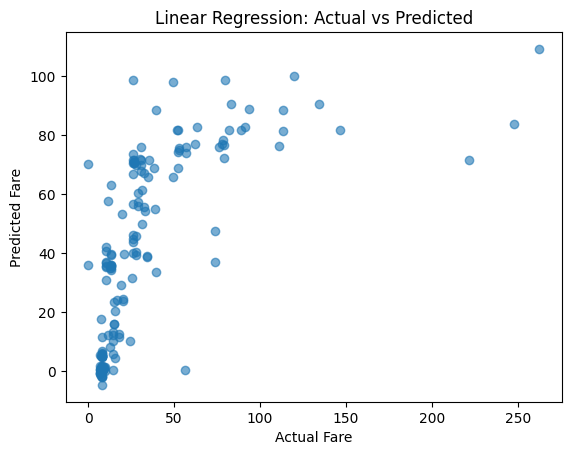

In [3]:
plt.scatter(yr_test, pred, alpha=0.6)
plt.xlabel("Actual Fare")
plt.ylabel("Predicted Fare")
plt.title("Linear Regression: Actual vs Predicted")
plt.show()

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5),
}
predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_test)
    print(name, "trained")

Logistic Regression trained
Decision Tree trained
Random Forest trained
KNN trained


In [5]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
results = []
for name, pred in predictions.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1-score": f1_score(y_test, pred),
    })
results_df = pd.DataFrame(results).round(3)
results_df

,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.804,0.775,0.743,0.759
1,Decision Tree,0.799,0.828,0.649,0.727
2,Random Forest,0.804,0.767,0.757,0.762
3,KNN,0.816,0.797,0.743,0.769


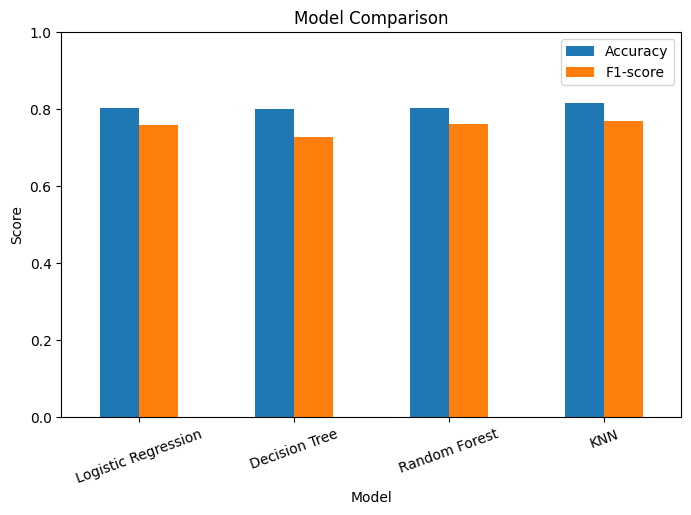

In [6]:
results_df.set_index("Model")[["Accuracy", "F1-score"]].plot(kind="bar", figsize=(8, 5))
plt.title("Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.show()

Best model: KNN


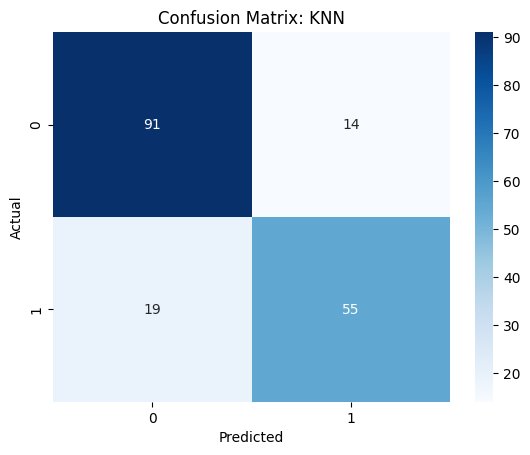

              precision    recall  f1-score   support

           0       0.83      0.87      0.85       105
           1       0.80      0.74      0.77        74

    accuracy                           0.82       179
   macro avg       0.81      0.80      0.81       179
weighted avg       0.81      0.82      0.81       179



In [7]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
best = results_df.sort_values("Accuracy", ascending=False).iloc[0]["Model"]
print("Best model:", best)
cm = confusion_matrix(y_test, predictions[best])
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"Confusion Matrix: {best}")
plt.show()
print(classification_report(y_test, predictions[best]))

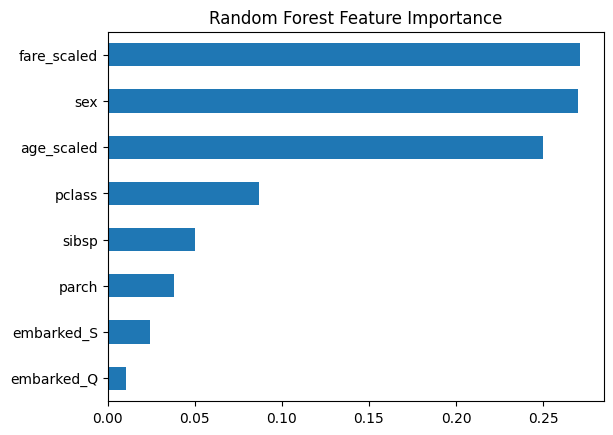

In [8]:
rf = models["Random Forest"]
importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
importance.plot(kind="barh", title="Random Forest Feature Importance")
plt.show()